# Младенческая смертность: карты и динамика

**Исследовательский вопрос:** как менялся уровень младенческой смертности в странах и территориях, представленных в HMD?

Работа состоит из трех частей:
1. Анализ полноты временных рядов данных для каждой из представленных стран (наличие пробелов в данных)
2. Построение карт распределения коэфф. младенческой смертности с 1990-го по 2020-й с промежутком каждые 5 лет
3. Анализ графиков коэфф. младенческой смертности по годам в Европейских странах

**Источник показателей:** [Human Mortality Database](https://www.mortality.org/),
HMD summary indicators: Infant mortality rate, обновление от 27 августа 2026 года.
Исходный Excel был преобразован в CSV без округления значений.
Одна строка CSV - страна/территория и год; в файле - 41 страна/территория.

**Единица:**  уровень смертности детей в возрасте до одного года на 1000 родившихся живыми за год.
Согласно описанию HMD, показатель приближенно оценивает вероятность умереть
в течение первого года жизни. 

**Источник географических границ государств:** [Natural Earth, масштаб 1:110 млн](https://www.naturalearthdata.com/),
public domain. Карта с крупными упрощениями является обзорной и не отображает реальные границы стран в каждый исторический период.

# Обоснование исследования

Младенческая смертность - один из демографических факторов, наиболее наглядно отражающих уровень развития страны и происходящие в ней экономические и социальные изменения (Е.А. Кваша, 2003 г.) . Младенческая смертность характеризует риск смерти ребенка в течение первого года жизни. Изучение этого показателя позволяет проследить, как менялась ситуация в разных странах и насколько сохранялись различия между ними. Кроме того подобное исследование позволит проследить, в каких странах показатель снизился сильнее, было ли снижение равномерным и были ли периоды роста. Карты за отдельные годы демонстрируют пространственное распределение показателя, а графики - изменения во времени.

In [5]:
%%writefile README.md
Младенческая смертность: карты и динамика

Учебный проект по курсу Python 2026 г.

Цель
Изучить изменения младенческой смертности и различия между странами по данному показателю.

Данные
Источник показателей: https://www.mortality.org/
Границы стран: https://www.naturalearthdata.com/

Что сделано
- Проверена полнота временных рядов для всех стран.
- Построены карты за 1990–2020 годы с интервалом в пять лет.
- Проанализирована динамика европейских стран за 2003–2013 годы.

Запуск 
Откройте Untitled.ipynb в Jupyter Notebook.
Выполните все ячейки последовательно сверху вниз.
Необходимые библиотеки: pandas, geopandas, matplotlib, numpy.

Автор
Андронова Ульяна Александровна, БГЕО251

Overwriting README.md


In [6]:
%pip install pandas geopandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [10]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

## 1. Читаем таблицу

В подготовленной таблице оставлены четыре столбца:
- `year` — год;
- `country` — название страны или территории;
- `iso3` — код для соединения с картой;
- `imr` — младенческая смертность на 1000 живорожденных.

CSV подготовлен из предоставленного Excel: общий показатель перенесен без
округления и заполнения пропусков. Для Франции, Германии, Новой Зеландии
и Великобритании использованы ряды `Total population`.
Отдельные группы населения и части стран не добавлены.
Строки заранее упорядочены по годам от ранних к поздним.


In [2]:
data = pd.read_csv('data/infant_mortality.csv', encoding='utf-8-sig')
data.head()

,year,country,iso3,imr
0,1751,Австралия,AUS,NaN
1,1751,Австрия,AUT,NaN
2,1751,Беларусь,BLR,NaN
3,1751,Бельгия,BEL,NaN
4,1751,Болгария,BGR,NaN


## 2. Анализ полноты временных рядов

График показывает, за какие годы доступны данные о младенческой смертности для каждой страны. Голубые ячейки обозначают наличие показателя, белые – отсутствие данных. Важно, что отсуствие значения не значит отсутствие младенческой смертности.

Проверка полноты временных рядов необходима для выбора стран и периода дальнейшего сравнения. Продолжительность рядов различается: у некоторых стран отсутствуют ранние наблюдения, у других – данные за последние годы.

<Figure size 3000x1500 with 0 Axes>

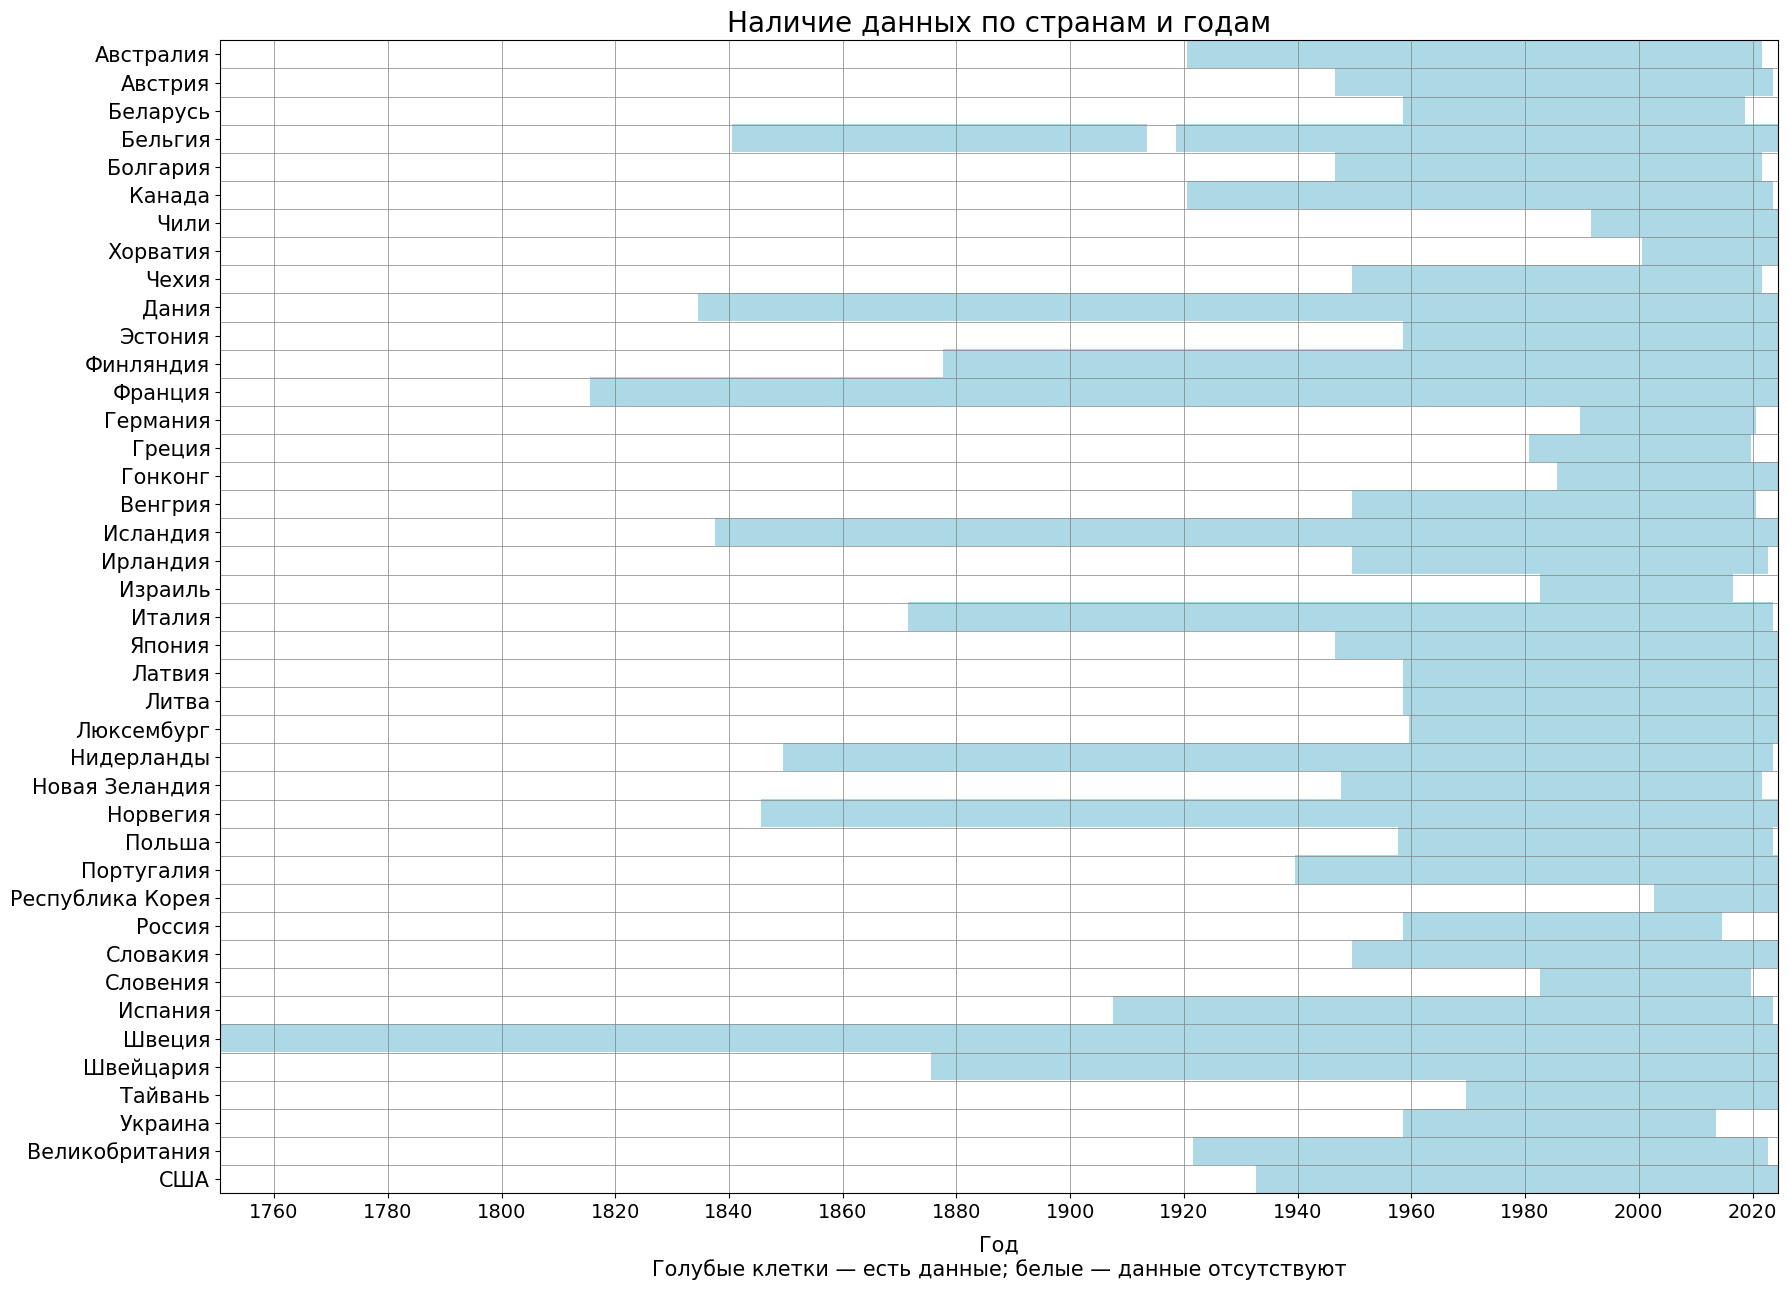

In [3]:
years = list(range(1751, 2025))  # Список годов, необходимых для исследования
countries = data['country'].unique()  # Создаем список с названиями стран без повторений
 
availability = []  # Составляем таблицу наличия данных

for country in countries:
    country_data = data[data['country'] == country]
    row = []
    for year in years:
        year_data = country_data[country_data['year'] == year]
        known_data = year_data.dropna(subset=['imr'])  # Исключаем строки, в которых показатель смертности отсутствует.
        if len(known_data) > 0:
            row.append(1)
        else:
            row.append(0)

    availability.append(row)

plt.figure(figsize=(30, 15))  # Рисуем таблицу цветными ячейками
tick_positions = []
tick_years = []

for i in range(len(years)):
    if years[i] % 20 == 0:
        tick_positions.append(i)
        tick_years.append(years[i])

plt.figure(figsize=(18, 13))

colors = ListedColormap(['white', 'lightblue'])

plt.imshow(
    availability,
    cmap=colors,
    aspect='auto',
    interpolation='nearest',
    vmin=0,
    vmax=1
)

plt.xticks(tick_positions, tick_years, fontsize=14)  # Подписываем только выбранные годы
plt.yticks(range(len(countries)), countries, fontsize=15)

for position in tick_positions:  # Вертикальная сетка через 20 лет
    plt.axvline(position, color='grey', linewidth=0.5)

for i in range(1, len(countries)):
    plt.axhline(i - 0.5, color='grey', linewidth=0.5)

plt.title('Наличие данных по странам и годам', fontsize=20)

plt.xlabel(
    'Год\nГолубые клетки — есть данные; белые — данные отсутствуют',
    fontsize=15,
    labelpad=10
)

plt.tight_layout()
plt.show()

## Выводы о полноте данных
`Самый длинный ряд представлен для Швеции`(с 1751 года). Для большинства стран данные по младенческой смертности появляются с середины XIX в.
`Наиболее поздно начинается ряд Республики Корея – в 2003 году.`

Различается и последний доступный год наблюдений: для некоторых стран данные доходят до 2024 года. `Однако, общий последний год – 2013` Например, ряд Украины завершается в 2013 году, России – в 2014 году. Кроме того, в отдельных исторических рядах встречаются внутренние пропуски, что заметно на примере Бельгии. 

`Общий непрерывный период для всех представленных стран – 2003–2013 годы.` Таким образом, для анализа динамики изменения данное десятилетие будет оптимальным. Однако для картографического анализа выбран более продолжительный период – `с 1990 по 2020 год` с интервалом в `5 лет`. Такой период позволяет проследить долгосрочные изменения пространственного распределения младенческой смертности, которые могут быть менее заметны за одно десятилетие.

Ниже представлено количество географических единиц, для которых доступны данные о младенческой смертности в выбранные годы с 1990 по 2020 год с интервалом в пять лет.

In [4]:
years = [1990, 1995, 2000, 2005, 2010, 2015, 2020]

for year in years:
    year_data = data[data['year'] == year]
    known_data = year_data.dropna(subset=['imr'])  # Исключаем строки, в которых показатель смертности отсутствует.
    print(year, '– стран и территорий с данными:', len(known_data))

1990 – стран и территорий с данными: 38
1995 – стран и территорий с данными: 39
2000 – стран и территорий с данными: 39
2005 – стран и территорий с данными: 41
2010 – стран и территорий с данными: 41
2015 – стран и территорий с данными: 39
2020 – стран и территорий с данными: 35


## 3. Читаем границы стран

`gpd.read_file` читает файл с географическими границами.
Получается таблица, в которой столбец `geometry` содержит форму каждой страны.
В ней уже есть тот же ключ `iso3`, что и в таблице показателей.

Границы взяты из Natural Earth (масштаб 1:110 млн). В подготовленном файле
оставлены название, код и исходная геометрия; Антарктида исключена.
Некоторые небольшие территории, например Гонконг, в таком масштабе
не имеют отдельного полигона.


In [5]:
world = gpd.read_file('data/world.geojson')
world.head()

,name,iso3,geometry
0,Fiji,FJI,"MULTIPOLYGON (((180 -16.06713, 180 -16.55522, ..."
1,United Republic of Tanzania,TZA,"POLYGON ((33.90371 -0.95, 34.07262 -1.05982, 3..."
2,Western Sahara,ESH,"POLYGON ((-8.66559 27.65643, -8.66512 27.58948..."
3,Canada,CAN,"MULTIPOLYGON (((-122.84 49, -122.97421 49.0025..."
4,United States of America,USA,"MULTIPOLYGON (((-122.84 49, -120 49, -117.0312..."


## 4. Строим карты (ура география)

Сначала находим максимум среди четырёх срезов. Он задаёт верхнюю границу
**одной и той же цветовой шкалы** на всех картах. Минимальное значение – `0`, поскольку ниже него коэффициент быть не может.

In [6]:
color_max = 0  # Переменная для поиска самого большого значения.

for year in years:
    year_data = data[data['year'] == year]   # Выбираем данные за текущий год.
    year_max = year_data['imr'].max()  # Находим максимальное значение показателя за этот год.
    if year_max > color_max:
        color_max = year_max

print('Общая шкала карт: от 0 до', color_max)

Общая шкала карт: от 0 до 19.06


Далее – соединение таблиц и построение карты:

- `world.merge(year_data, on='iso3', how='left')` находит для каждого полигона
  показатель той же страны. `how='left'` сохраняет все полигоны, в том числе
  страны без данных.
- `.plot(column='imr')` раскрашивает страны по этому столбцу.
- `cmap='YlOrRd'` задаёт переход от жёлтого к красному.
- `vmin` и `vmax` задают общую шкалу; `legend=True` добавляет шкалу значений.
- `missing_kwds` задаёт серый цвет для стран без данных.


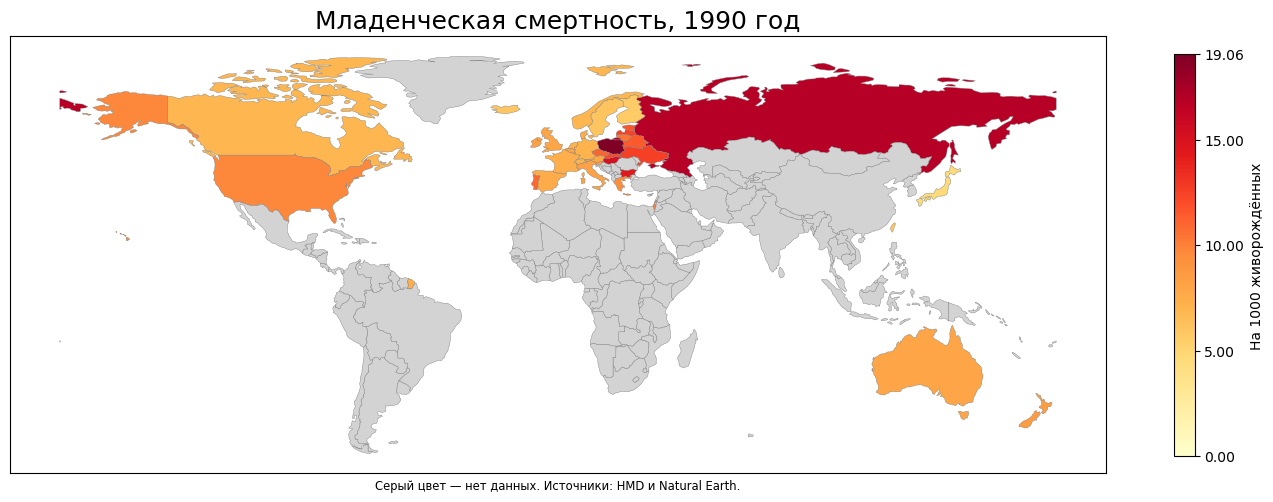

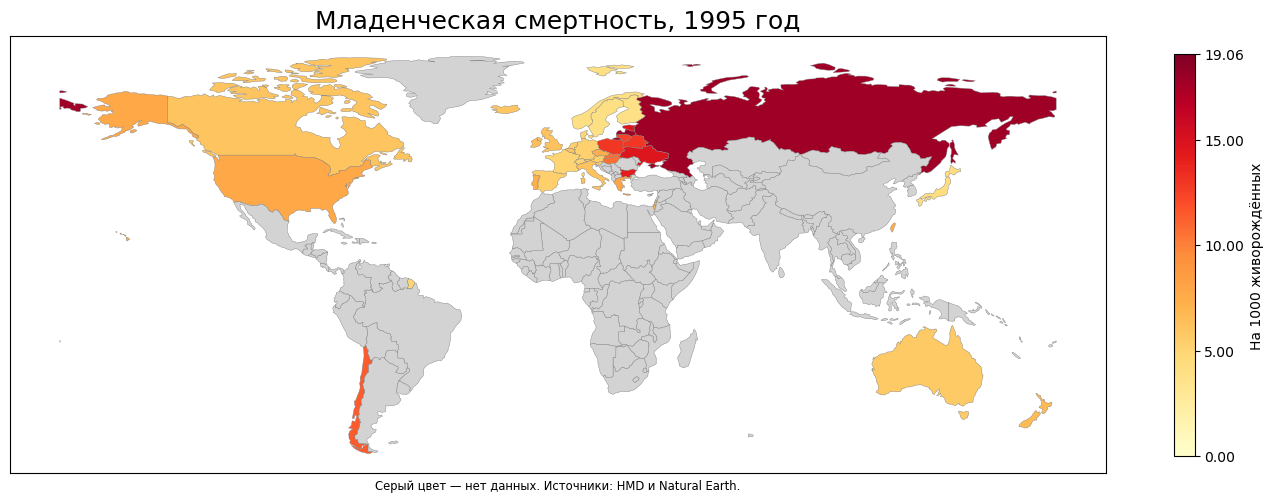

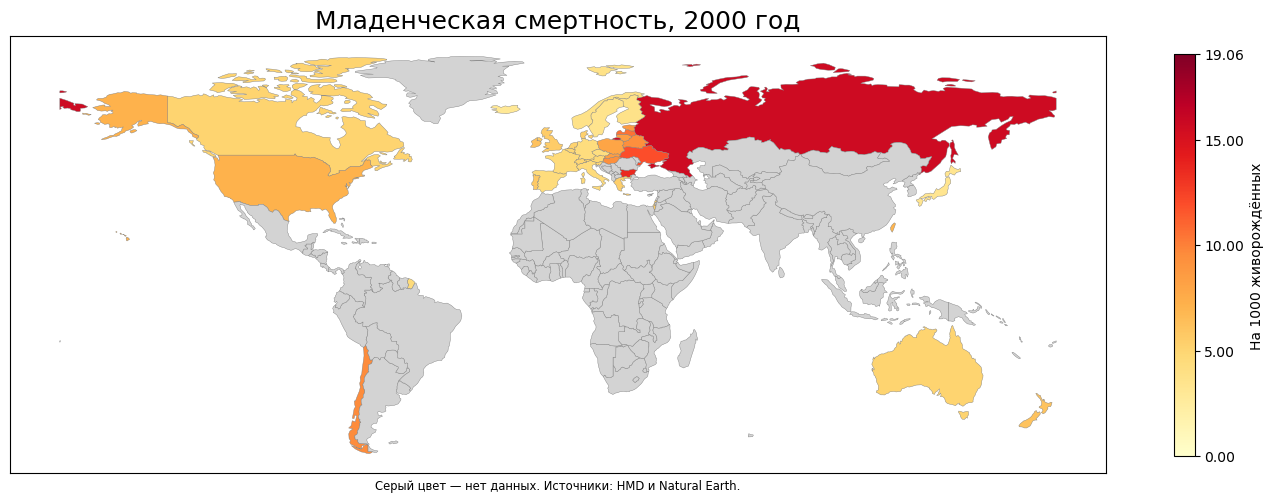

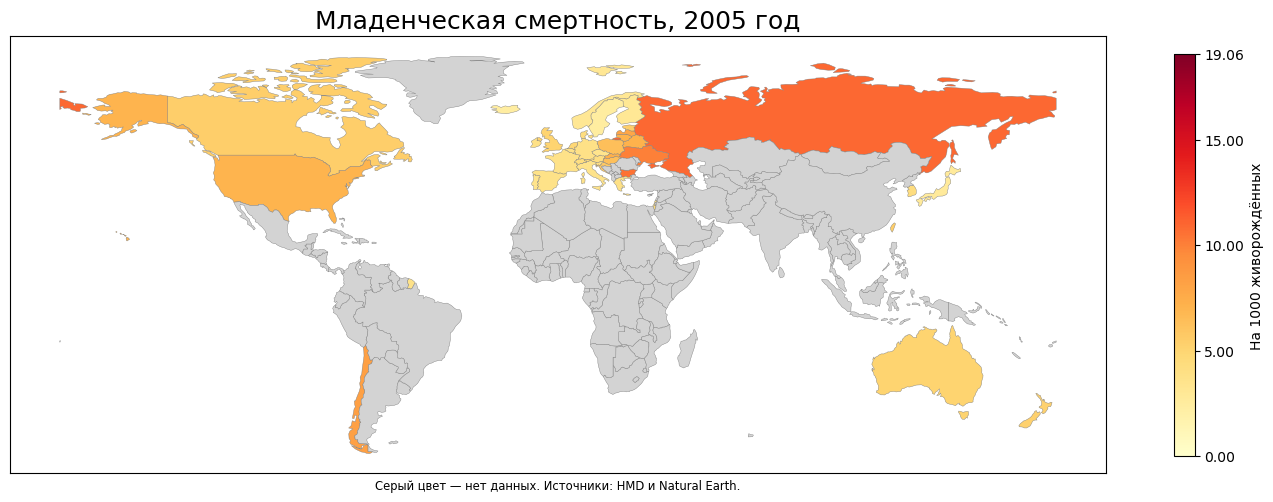

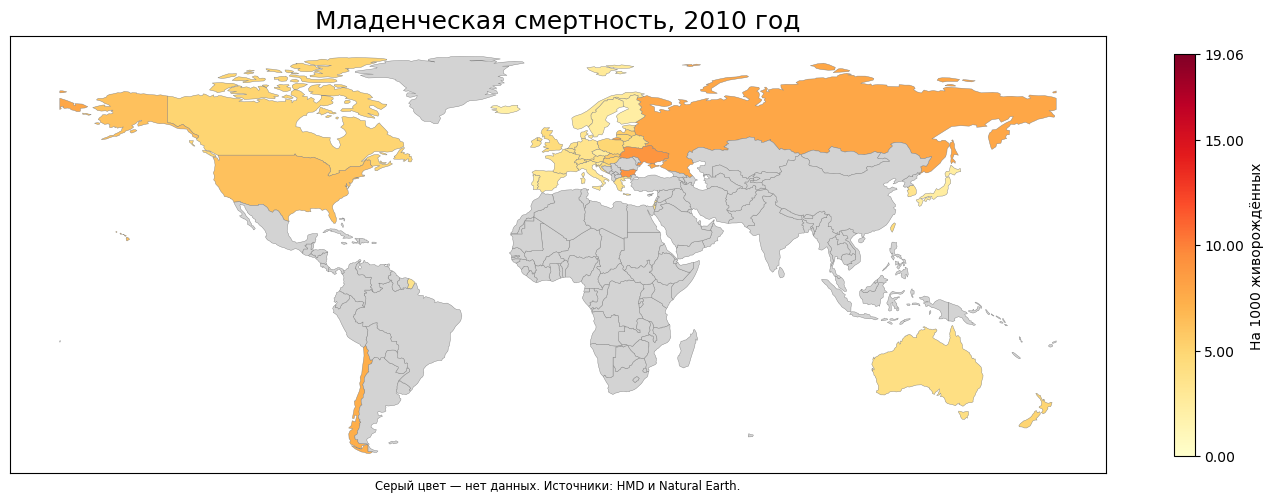

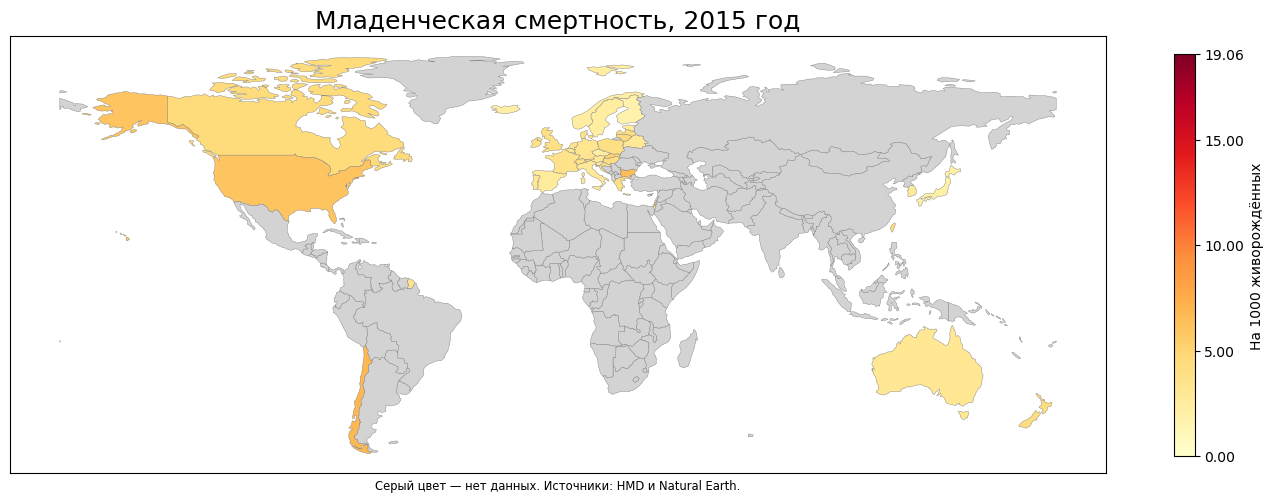

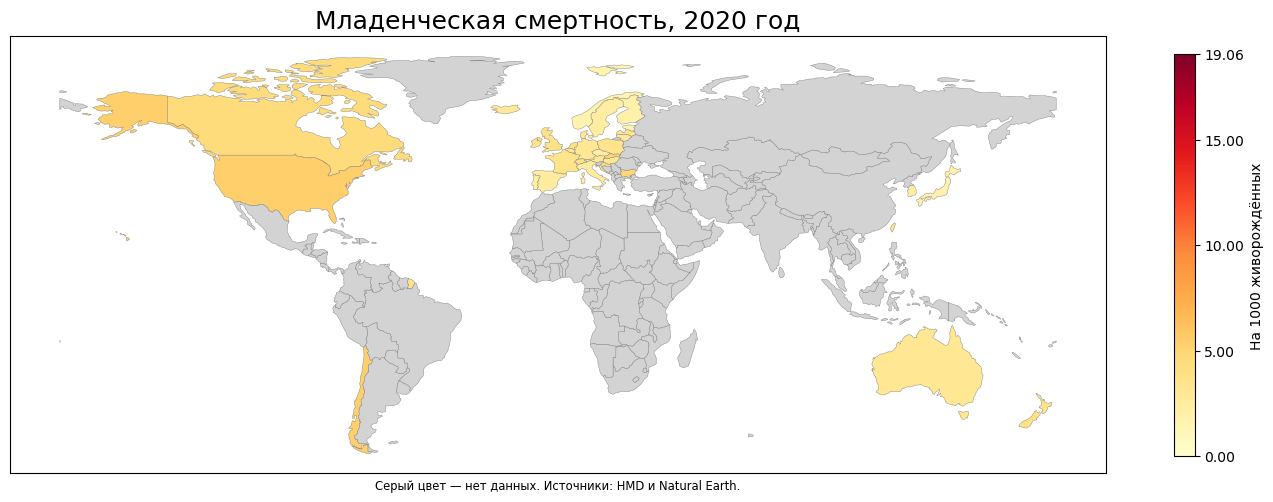

In [7]:
for year in years:
    year_data = data[data['year'] == year]
    map_data = world.merge(year_data, on='iso3', how='left')  # how='left' сохраняет на карте страны без данных.

    fig, ax = plt.subplots(figsize=(14, 7))  # Раскрашиваем страны по значению младенческой смертности используя одну цветовую шкалу.
    map_data.plot(
        column='imr', ax=ax, cmap='YlOrRd',
        vmin=0, vmax=color_max, legend=True,
        edgecolor='grey', linewidth=0.3,
        missing_kwds={'color': 'lightgrey'},
        legend_kwds={
        'label': 'На 1000 живорождённых',
        'shrink': 0.6,
        'ticks': [0, 5, 10, 15, color_max]
    }
    )
    ax.set_title(f'Младенческая смертность, {year} год', fontsize=18)
    ax.set_xlabel('Серый цвет — нет данных. Источники: HMD и Natural Earth.')
    ax.set_ylabel('')
    ax.set_xticks([])
    ax.set_yticks([])
    plt.tight_layout()
    plt.savefig(f'figures/map_{year}.png', dpi=150)
    plt.show()

## 5. Анализ динамики изменения коэффициента младенческой смертности

Для анализа европейские страны, представленные в наборе данных, разделены на четыре региона: `Северную, Западную, Восточную и Южную Европу`. Основой разделения является классификация ООН M49. Согласно ей, страны Балтии относятся к Северной Европе, а Россия, Польша и Чехия – к Восточной. Такое разделение позволяет сохранить графики читаемыми и сравнить изменения показателя внутри регионов.

Для каждого региона построен два отдельных графика: динамики фактических значений коэффициента младенческой смертности за `2003–2013 годы` (период, за который у всех рассматриваемых стран имеются непрерывные данные) и линии тренда для каждой страны за этот же период. Для сопоставления уровня младенческой смертности между регионами была выбрана одинаковая вертикальная шкала.

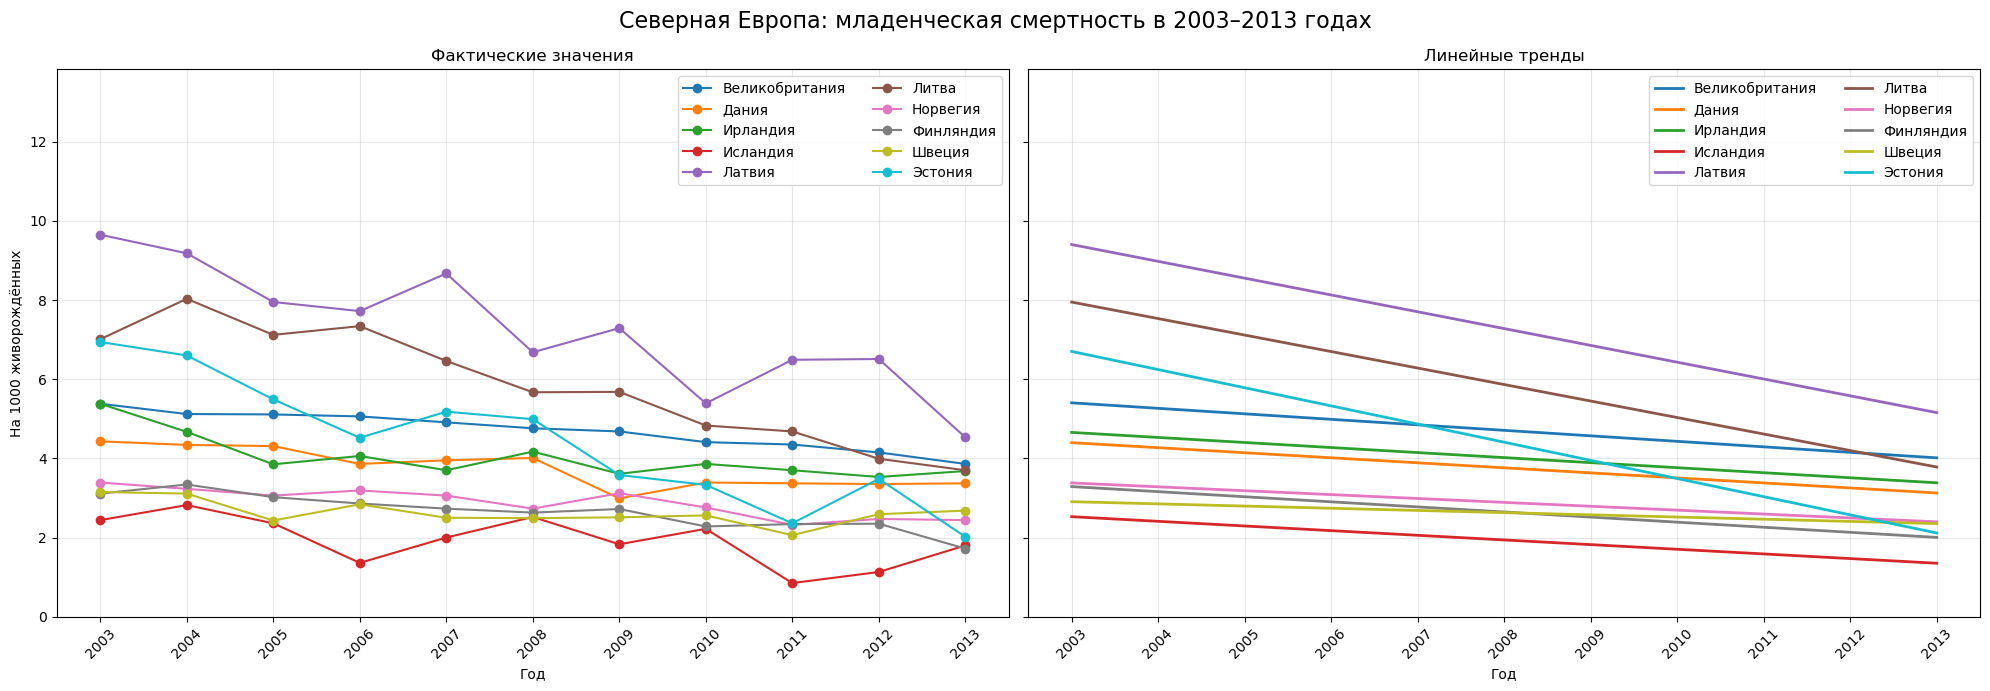

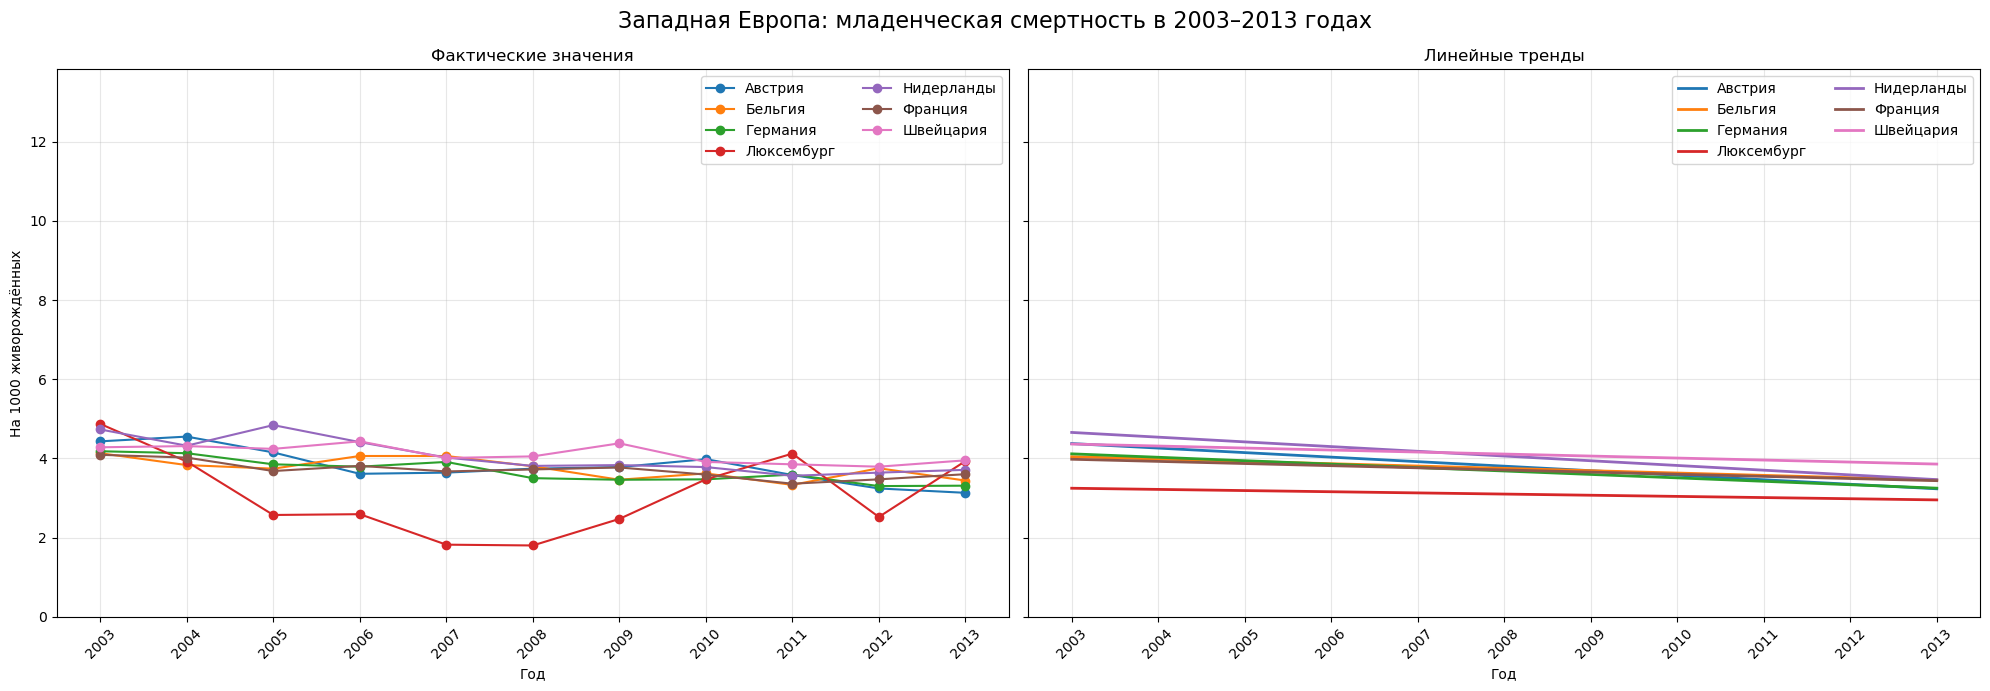

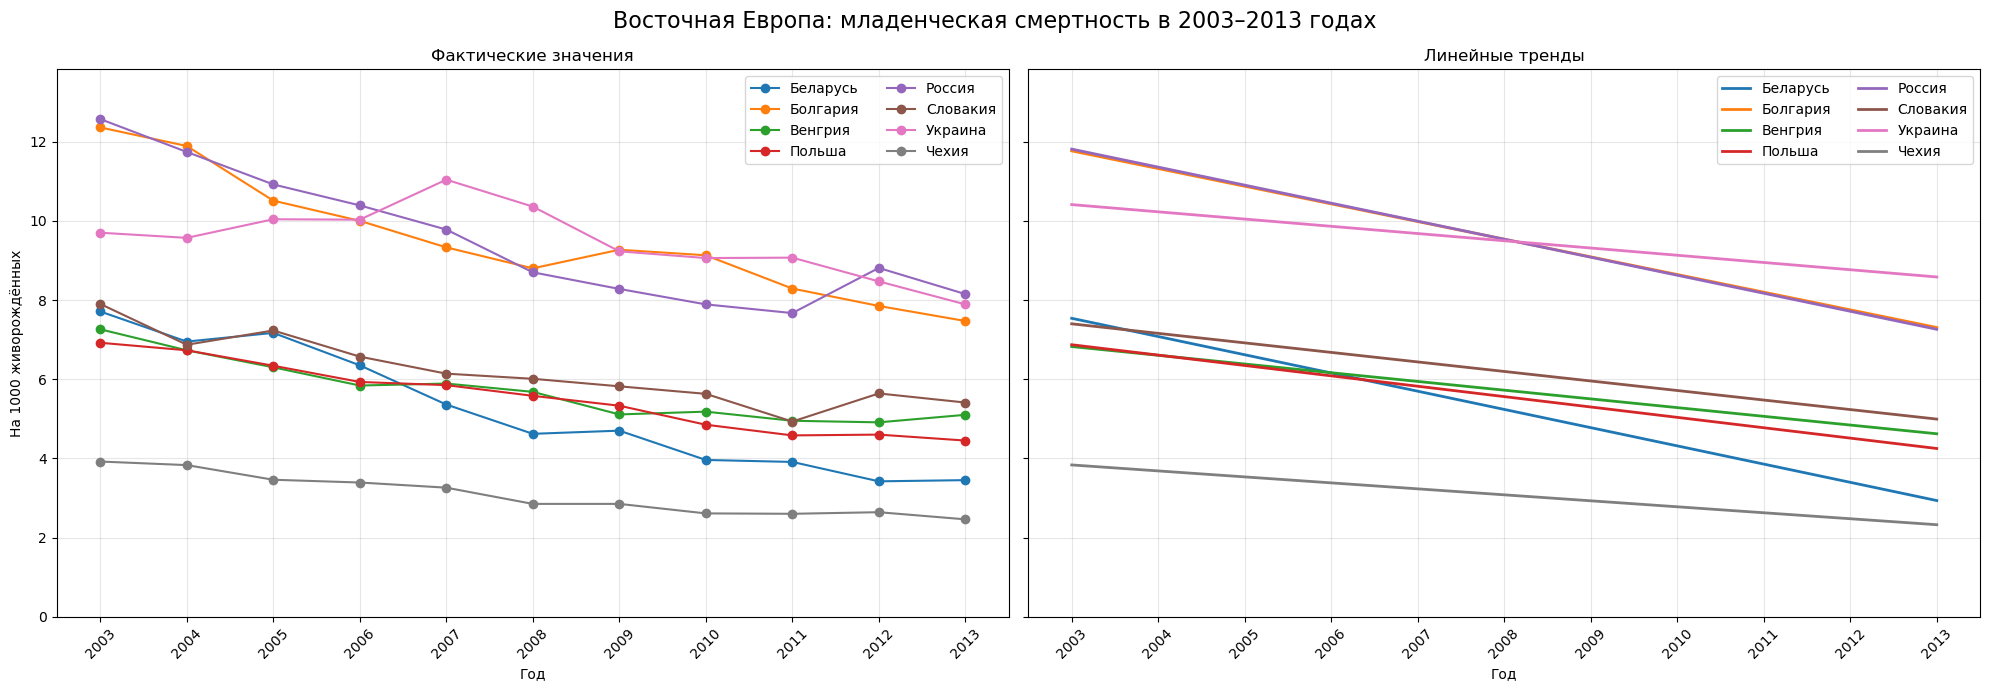

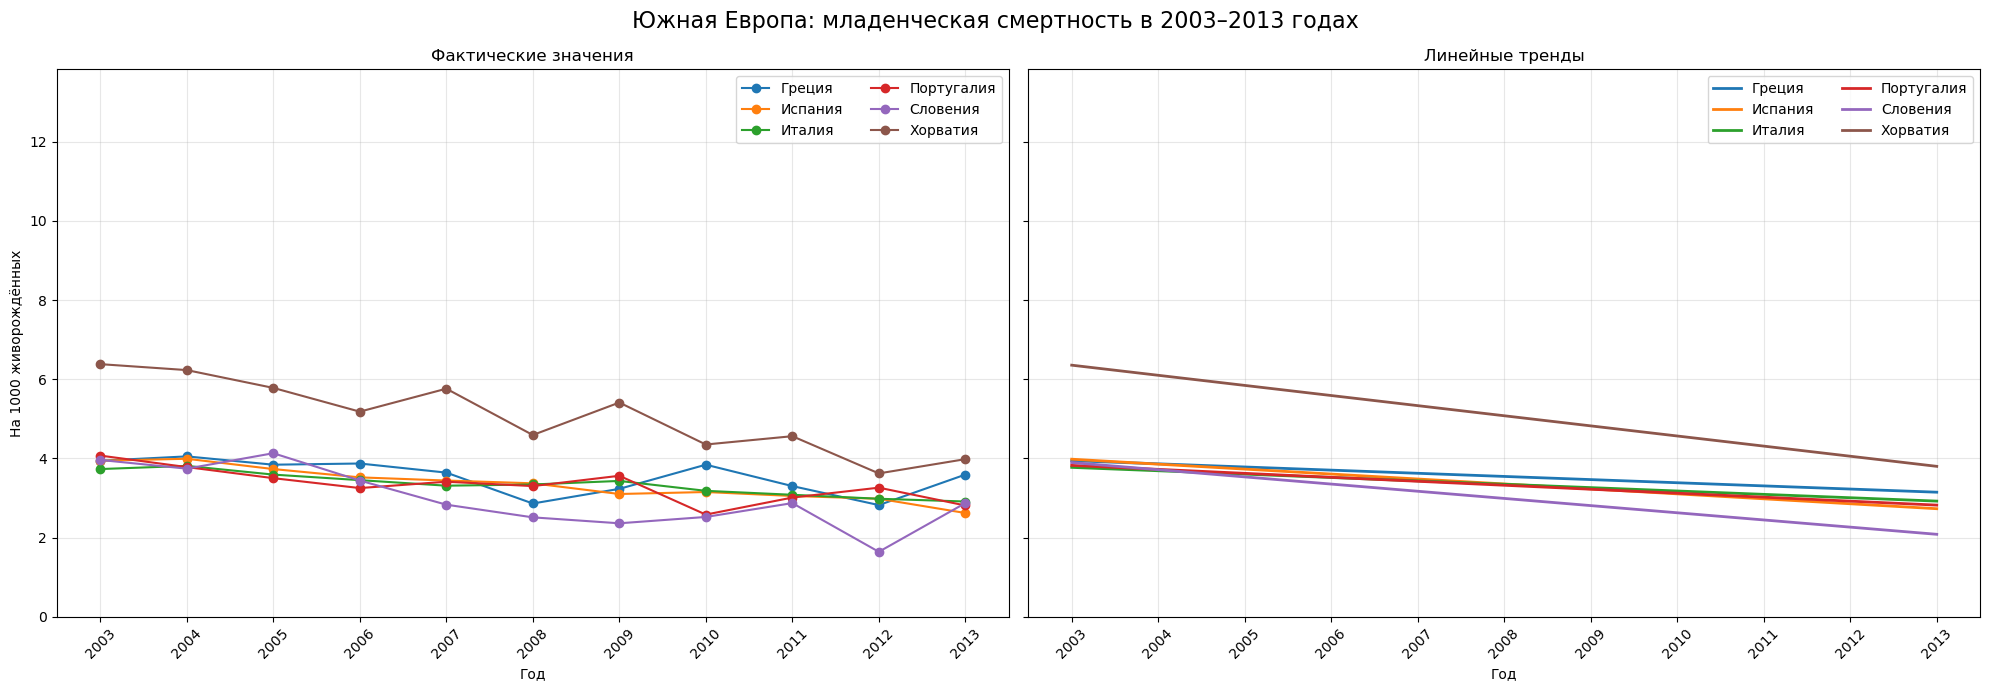

In [11]:
years = list(range(2003, 2014))
regions = {
    'Северная Европа': [
        'Великобритания', 'Дания', 'Ирландия', 'Исландия',
        'Латвия', 'Литва', 'Норвегия', 'Финляндия',
        'Швеция', 'Эстония'
    ],
    'Западная Европа': [
        'Австрия', 'Бельгия', 'Германия', 'Люксембург',
        'Нидерланды', 'Франция', 'Швейцария'
    ],
    'Восточная Европа': [
        'Беларусь', 'Болгария', 'Венгрия', 'Польша',
        'Россия', 'Словакия', 'Украина', 'Чехия'
    ],
    'Южная Европа': [
        'Греция', 'Испания', 'Италия',
        'Португалия', 'Словения', 'Хорватия'
    ]
}
period_data = data[data['year'].isin(years)]

y_max = period_data['imr'].max()  # Общая шкала для сравнения графиков

for region in regions:  # Создаём два графика рядом с одинаковыми шкалами.
    fig, axes = plt.subplots(
        1, 2, figsize=(20, 7), sharex=True, sharey=True
    )

    for country in regions[region]:
        country_data = period_data[period_data['country'] == country]
        country_data = country_data.sort_values('year')

        axes[0].plot(
            country_data['year'],
            country_data['imr'],
            label=country,
            marker='o'
        )

        # Находим наклон и свободный член прямой линии тренда.
        slope, intercept = np.polyfit(
            country_data['year'],
            country_data['imr'],
            1
        )
        trend = slope * country_data['year'] + intercept   # Рассчитываем значения линии тренда для каждого года.

        # Справа показываем линию тренда каждой страны.
        axes[1].plot(
            country_data['year'],
            trend,
            label=country,
            linewidth=2
        )

    axes[0].set_title('Фактические значения')
    axes[1].set_title('Линейные тренды')

    for ax in axes:
        ax.set_xlabel('Год')
        ax.set_xticks(years)
        ax.tick_params(axis='x', labelrotation=45)
        ax.set_ylim(0, y_max * 1.1)
        ax.legend(fontsize=10, ncol=2)
        ax.grid(alpha=0.3)

    axes[0].set_ylabel('На 1000 живорождённых')

    fig.suptitle(
        f'{region}: младенческая смертность в 2003–2013 годах',
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

## Выводы по анализу графиков 

**Общая динамика**

Заметно, что для всех представленных в датасете стран характерно `снижение` коэффициента младенческой смертности `с 2003 по 2013`. Такую динамику демонстрируют как графики фактических значений, так и графики трендов. При этом фактические значения, конечно, снижались неравномерно. Наибольшее снижение младенческой смертности наблюдаются в `Северной и Восточной Европе`. В странах Западной Европы значения менялись незначительно. Уменьшение младенческой смертности связано с различными факторами, однако общими являются:
1. Развитие перинатальной и неонатальной помощи
2. Улучшения качества наблюдения за беременными
3. Внедрение средств ранней диагности

**Северная Европа**

В Северной Европе наблюдаются значительные различия между странами рассматриваемой выборки, особенно в начале периода. В 2003 году выделялись Латвия, Литва и Эстония, где коэффициент младенческой смертности составлял примерно 7–10 случаев на 1000 живорождённых. В остальных странах региона значения не превышали 5.5.

Максимальный показатель в 2003 году наблюдался в `Латвии` – 9.65. К 2013 году он снизился до 4.53, однако оставался самым высоким среди рассматриваемых стран Северной Европы. Снижение происходило неравномерно: на графике заметны локальные повышения в 2007 и 2009 годах, а также в 2011–2012 годах. 

Самое сильное относительное снижение внутри группы произошло в `Эстонии`: с 6.94 до 2.02, или на 70.9%. В результате к концу периода страна приблизилась к государствам с наиболее низкой младенческой смертностью. В `Литве` показатель также значительно сократился – с 7.01 до 3.70.

Важно понимать, что высокие коэффициенты младенческой смертности в 2003 г. в странах социального блока могут быть обусловлены последствиями экономического спада после [распада Советского Союза](https://ru.wikipedia.org/wiki/%D0%A0%D0%B0%D1%81%D0%BF%D0%B0%D0%B4_%D0%A1%D0%A1%D0%A1%D0%A0?ysclid=mvik2a8hyb392250335) (кризисы 90-х годов). В результате сокращения финансирования здравоохранения оснащенность больниц, квалификации кадров и доступности современных методов лечения оставляли желать лучшего, что приводило к летальным исходам среди новорожденных. 


Относительно низкие значения на протяжении периода наблюдались в `Исландии, Финляндии, Швеции и Норвегии`. При этом в `Исландии` заметны ежегодные колебания. Для небольших стран такие изменения могут частично объясняться небольшим числом рождений: несколько дополнительных смертей заметно влияют на коэффициент.

В `Великобритании, Ирландии и Дании` наблюдалось более плавное снижение. К 2013 году их показатели составляли примерно 3.4 – 3.9 случая на 1000 живорождённых. Наименьшие значения в конце периода были в `Финляндии` – 1.72 и `Исландии` – 1.80.

За рассматриваемый период различия внутри региона сократились: разрыв между максимальным и минимальным значениями уменьшился примерно с 7.2 до 2.8 случая на 1000 живорожденных.


**Западная Европа**

В Западной Европе наблюдаются небольшие различия между странами рассматриваемой выборки. В 2003 году коэффициент младенческой смертности составлял от 4.09 во `Франции` до 4.87 в `Люксембурге`. К 2013 году во всех семи странах показатель снизился.

Наиболее значительное снижение произошло в `Австрии`: с 4.43 до 3.13 случая на 1000 живорожденных, или на 29.3%. К концу периода страна имела самый низкий показатель внутри группы. Заметное снижение также наблюдалось в `Нидерландах` – с 4.73 до 3.71 и `Германии` – с 4.18 до 3.31. 

В `Бельгии` коэффициент сократился с 4.13 до 3.44, а во `Франции` с 4.09 до 3.60. 

На фоне остальных стран выделяется `Люксембург`, где наблюдались выраженные колебания. После снижения примерно до 1.8 в 2007–2008 годах показатель вновь вырос, затем сократился в 2012 году и увеличился в 2013 году. Здесь ситуация аналогичная с Исландией, где незначительное количество смертей влиют на статистику.

Таким образом, для Западной Европы характерно снижение младенческой смертности при сохранении близких значений между странами. При этом выраженного сокращения разрыва внутри группы не произошло: разница между максимальным и минимальным показателями составляла около 0,8 случая на 1000 живорожденных как в начале, так и в конце периода.

**Восточная Европа**

Здесь наблюдаются наиболее значительные различия между странами рассматриваемой выборки. В 2003 году выделяется группа стран `(Словакия, Беларусь, Венгрия, Польша)` с показателем смертности 7–8. 

Наименьший коэффициент наблюдался в `Чехии`, снизившийся с 3.92 до 2.46 за рассматриваемый период.

В 2003 году максимальные значения были в `России` – 12.57, после чего происходила снижение показателя. Однако на графике заметен локальный пик с 2011 по 2012. Такое увеличение связано с переходом России к новым критериям регистрации живорождения, что позволило приблизить критерии к рекомендациям ВОЗ. В статистике стали полнее учитываться дети, родившиеся на сроке от 22 недель с массой от 500 граммов, среди которых риск смерти особенно высок. 

В `Украине` в 2005–2007 годах произошло увеличение показателя примерно до 11 случаев на 1000. В 2007 году вступили в силу новые правила определения живорождения и мертворождения, соответствующие рекомендациям ВОЗ. Кроме того, авторы документации базы смертности предполагают, что изменения с 2005 года могли быть связаны с переходом на МКБ-10 и более тщательной регистрацией смертей младенцев.

Самое сильное снижение внутри группы произошло в `Беларуси`: с 7.71 до 3.45, или на 55.3%. 

**Южная Европа**

В Южной Европе наиболее высокий коэффициент младенческой смертности наблюдался в `Хорватии`: в 2003 году он составлял 6.38 случая на 1000 живорожденных. К 2013 году показатель снизился до 3.98, или на 37.6%. Возможно, что высокие значения относительно других стран в регионе вызваны распадом [Югославии.](https://ru.wikipedia.org/wiki/%D0%A0%D0%B0%D1%81%D0%BF%D0%B0%D0%B4_%D0%AE%D0%B3%D0%BE%D1%81%D0%BB%D0%B0%D0%B2%D0%B8%D0%B8?ysclid=mvijzdicxs968902286#%D0%9F%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D1%81%D1%82%D0%B2%D0%B8%D1%8F)

В остальных странах начальные значения были близкими – примерно 3.7 – 4.1. В `Испании, Италии и Португалии` наблюдалось общее снижение, и к 2013 году их показатели составляли около 2.6 – 2.9 случая на 1000 живорожденных.

В `Греции` снижение за весь период оказалось наименьшим — с 3.94 до 3.59, или на 8.9%. Отдельные повышения после 2008 года могли происходить на фоне экономического [кризиса](https://translated.turbopages.org/proxy_u/en-ru.ru.aaadede4-6ad91ca1-1546550a-74722d776562/https/en.wikipedia.org/wiki/Greek_government-debt_crisis). 



## Выводы

В ходе работы была проведена проверка полноты временных рядов для 41 страны и территории, представленных в HMD. Она показала, что продолжительность наблюдений различается, а общий непрерывный период составляет 2003–2013 годы. Это позволило выбрать сопоставимый период для анализа динамики. Для изучения долгосрочных пространственных изменений были построены карты за 1990–2020 годы с интервалом в пять лет.

Карты показали общее снижение младенческой смертности в странах с данными за начало и конец периода. Анализ графиков за 2003–2013 годы также показал, что во всех рассматриваемых европейских странах значения к концу периода были ниже, чем в начале. Однако снижение происходило неравномерно: наблюдались периоды роста и ежегодные колебания.

### Материалы курса, на которые опирается код

- [Лекция 2: циклы и списки](https://github.com/teimy/geohse-python/blob/main/Lectures/Lecture2/Lecture2.ipynb).
- [Лекция 3: функции](https://github.com/teimy/geohse-python/blob/main/Lectures/Lecture3/Lecture3.ipynb).
- [Лекция 5: словари и документирование](https://github.com/teimy/geohse-python/blob/main/Lectures/Lecture5/Lecture5.ipynb).
- [Лекция 7: Matplotlib](https://github.com/teimy/geohse-python/blob/main/Lectures/Lecture7/Lecture7.ipynb).
- [Лекция 8: фильтрация, pandas и CSV](https://github.com/teimy/geohse-python/blob/main/Lectures/Lecture8/Lecture8.ipynb).

### Источники данных

- Human Mortality Database (2026). HMD summary indicators: Infant mortality rate.
  Max Planck Institute for Demographic Research; University of California,
  Berkeley; French Institute for Demographic Studies. Обновление: 27.08.2026.
  Файл предоставлен пользователем 19.10.2026. [Сайт HMD](https://www.mortality.org/).
- [Границы Natural Earth](https://github.com/nvkelso/natural-earth-vector/blob/master/geojson/ne_110m_admin_0_countries.geojson),
  масштаб 1:110 млн; [public domain](https://www.naturalearthdata.com/about/terms-of-use/).
  В подготовленном слое `iso3` взят из `ISO_A3_EH`, что обеспечивает сопоставление
  в том числе Франции и Норвегии. Геометрия не изменена.
